# GutSignal — от анализа данных до обоснованного сабмита

**Задача:** предсказать наличие колоректального рака (`label=1`) против контроля (`label=0`) по кишечному микробиому. Одна история в одном воспроизводимом ноутбуке: **EDA → данные и риски → валидация → 7 моделей → новые признаки → две финальные стратегии → проверка переноса между странами → сабмит**.

**Что сдаём:** `.ipynb` и `submission.csv`. Последняя ячейка выводит **ровно две колонки**: `sample_id` и `label`, где `label` — **вероятность класса 1** (от 0 до 1), а не бинарная метка.

**Ограничения:** только `train.csv` и `test.csv`; `sample_id` и `cohort` не используются как входные признаки (страна служит для диагностики и стратификации), нет внешних данных и весов. Все обучаемые преобразования выполняются внутри обучающего фолда. Test читается только после завершения валидации и выбора финального решения.

**На основе двух исходных ноутбуков:** `GutSignal_Simple_EDA(1).ipynb` и `GutSignal_7_Models_Comparison_executed (4).ipynb`. От повторяющихся и конфликтующих ячеек отказались; оценки ниже **пересчитываются** на единой схеме и не подставляются из старых запусков.

## 0. Окружение и воспроизводимость

Используем pandas, matplotlib, scikit-learn, CatBoost, LightGBM и XGBoost. В Colab при отсутствии библиотек устанавливаются только пакеты Python — никакие внешние данные и предобученные веса не загружаются. Для сравнимости ограничиваем CPU двумя потоками и фиксируем seed.

In [1]:
import importlib.util
import subprocess
import sys

missing = [p for p in ("catboost", "lightgbm", "xgboost")
           if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 115
plt.rcParams["font.family"] = "DejaVu Sans"
RESULTS_DIR = Path("gutsignal_results")
RESULTS_DIR.mkdir(exist_ok=True)
print("Библиотеки готовы. CPU, seed =", SEED)

Библиотеки готовы. CPU, seed = 42


## 1. Разведочный анализ данных (EDA)

Сначала проверим форму таблицы, классы, пропуски, дубликаты и число нулей. В микробиоме нули естественны и **не приравниваются к пропускам**. Для EDA допустимо смотреть связи с `label` на всём train; **не используем этот глобальный список для отбора признаков во время CV**.

In [2]:
DATA_DIR = Path("/content") if Path("/content/train.csv").exists() else Path(".")
train = pd.read_csv(DATA_DIR / "train.csv")

TAXA = sorted(c for c in train.columns if "mOTU_v2_" in c)
NUM_COLS = TAXA + ["age", "bmi", "library_size"]
assert len(TAXA) == 849, f"Ожидается 849 таксонов, найдено {len(TAXA)}"
assert train["sample_id"].is_unique
assert set(train["label"].dropna().unique()) == {0, 1}

print("Размер train:", train.shape)
print("Количество таксонов:", len(TAXA))
print("Баланс меток:", train["label"].value_counts().sort_index().to_dict())
print("Пропуски:", train.isna().sum().loc[lambda s: s > 0].to_dict())
print("Дубликаты по признакам:",
      train.drop(columns=["sample_id", "label"]).duplicated().sum())
print("Доля нулей в микробных признаках:",
      round((train[TAXA] == 0).to_numpy().mean(), 4))

Размер train: (415, 856)
Количество таксонов: 849
Баланс меток: {0: 210, 1: 205}
Пропуски: {'bmi': 3}
Дубликаты по признакам: 0
Доля нулей в микробных признаках: 0.7197


### 1.1. Распределение классов по когортам

Группы `AUS`, `CHI`, `FRA`, `GER`, `USA` могут отличаться пропорцией больных и контрольных образцов. Поэтому далее используем **стратификацию по `cohort × label`** и отдельно проверяем перенос на исключённую страну.

label,Контроль,КРР
cohort,,
AUS,48,31
CHI,41,58
FRA,43,37
GER,44,43
USA,34,36


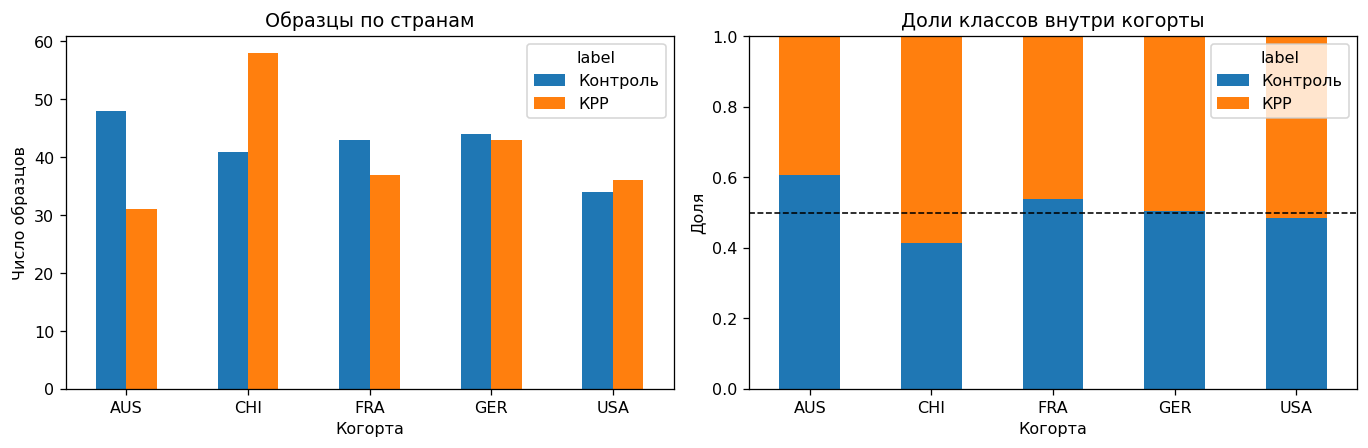

In [3]:
counts = pd.crosstab(train["cohort"], train["label"]).rename(
    columns={0: "Контроль", 1: "КРР"}
)
share = counts.div(counts.sum(axis=1), axis=0)
display(counts)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts.plot(kind="bar", ax=axes[0], rot=0, title="Образцы по странам")
axes[0].set(xlabel="Когорта", ylabel="Число образцов")
share.plot(kind="bar", stacked=True, ax=axes[1], rot=0,
           title="Доли классов внутри когорты")
axes[1].axhline(0.5, color="black", ls="--", lw=1)
axes[1].set(xlabel="Когорта", ylabel="Доля", ylim=(0, 1))
plt.tight_layout()
plt.show()

### 1.2. Ковариаты и дисбалансы

Возраст, BMI, пол и `library_size` потенциально связаны с меткой независимо от бактерий. Их **не выравниваем и не отбрасываем**: в основной модели они остаются числовыми признаками; страна исключена из обучения. Это не каузальная корректировка дисбаланса, а предиктивный подход.

Медианы по классам:


,age,bmi,library_size
label,,,
Контроль,63.0,24.45,23808971.0
КРР,66.0,25.65,26701988.0


Пол по классам (доли внутри класса):


gender,F,M
label,,
0,0.395,0.605
1,0.327,0.673


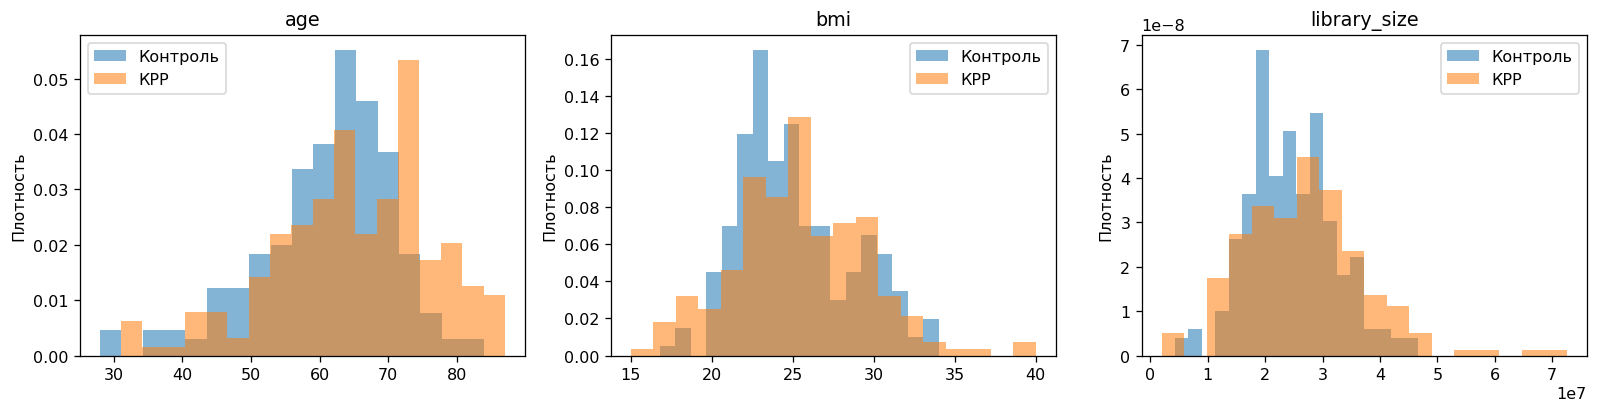

In [4]:
meta_num = ["age", "bmi", "library_size"]
print("Медианы по классам:")
display(train.groupby("label")[meta_num].median().rename(index={0:"Контроль",1:"КРР"}).round(2))
print("Пол по классам (доли внутри класса):")
display(pd.crosstab(train["label"], train["gender"], normalize="index").round(3))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for ax, col in zip(axes, meta_num):
    for label, txt in [(0,"Контроль"),(1,"КРР")]:
        ax.hist(train.loc[train.label.eq(label),col].dropna(), bins=18,
                alpha=.55, density=True, label=txt)
    ax.set_title(col)
    ax.set_ylabel("Плотность")
    ax.legend()
plt.tight_layout()
plt.show()

### 1.3. Корреляции Спирмена с меткой

Положительная корреляция означает, что более высокие значения признака чаще наблюдаются у `label=1`. Отрицательная — обратную связь. **Корреляция не доказывает причинность**, а множество нулей усложняет интерпретацию. Глобальный топ предназначен только для EDA и слайдов.

Топ-20 по |Spearman|:


,spearman
Parvimonas micra [ref_mOTU_v2_1145],0.4531
unknown Dialister [meta_mOTU_v2_5867],0.4097
Gemella morbillorum [ref_mOTU_v2_4513],0.3945
Fusobacterium nucleatum s. animalis [ref_mOTU_v2_0776],0.3887
Solobacterium moorei [ref_mOTU_v2_0531],0.3590
Peptostreptococcus stomatis [ref_mOTU_v2_4614],0.3427
unknown Clostridiales [meta_mOTU_v2_6105],0.3150
unknown Porphyromonas [meta_mOTU_v2_7656],0.3130
Porphyromonas uenonis [ref_mOTU_v2_4616],0.3063
Hungatella hathewayi [ref_mOTU_v2_0882],0.3033


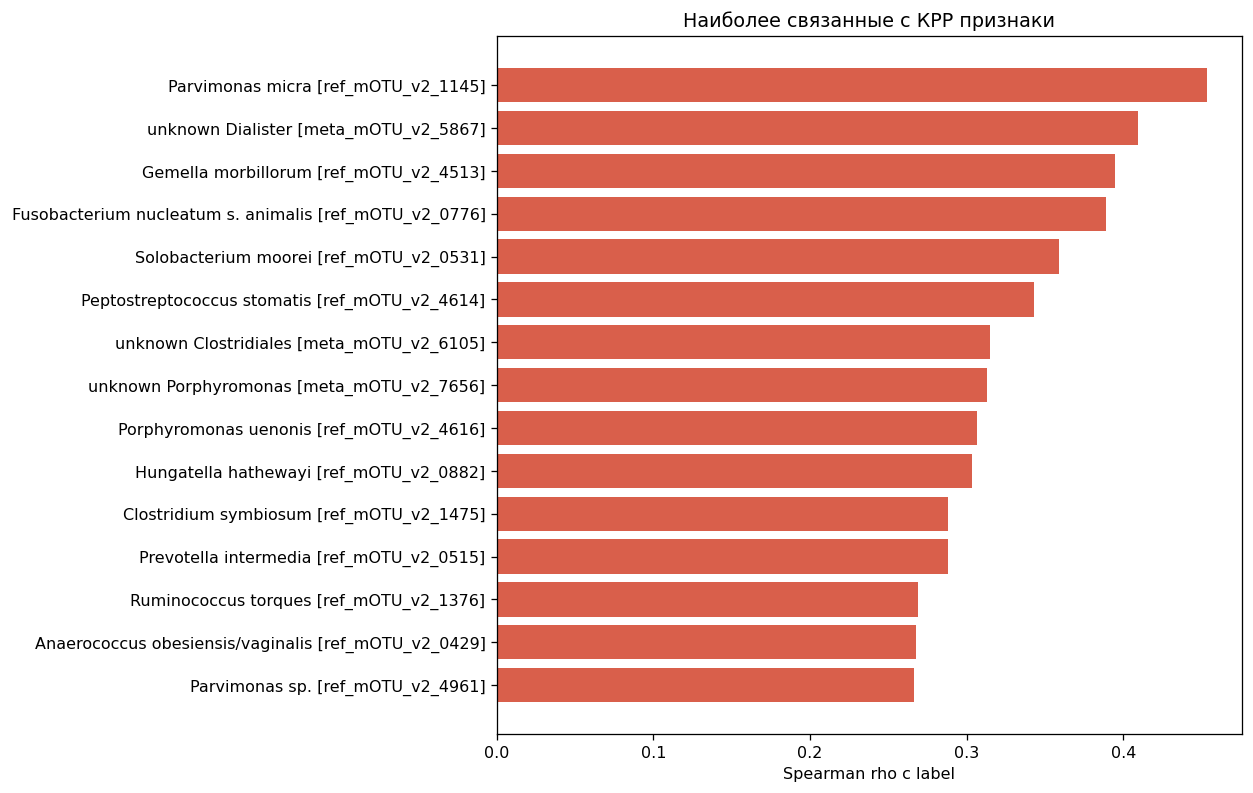

In [5]:
eda_num = train[NUM_COLS].copy()
eda_num["gender_M"] = train["gender"].map({"F":0, "M":1})
rho = eda_num.corrwith(train["label"], method="spearman").dropna()
rho = rho.sort_values(key=abs, ascending=False)
print("Топ-20 по |Spearman|:")
display(rho.head(20).to_frame("spearman").round(4))
fig, ax = plt.subplots(figsize=(11, 7))
chart = rho.head(15).sort_values()
ax.barh(chart.index, chart.values,
        color=["#D95F4B" if v > 0 else "#3975A9" for v in chart])
ax.axvline(0, color="black", lw=1)
ax.set(xlabel="Spearman rho с label", title="Наиболее связанные с КРР признаки")
plt.tight_layout()
plt.show()

## 2. Признаки и предобработка

Используем **все 849 численностей**, плюс `age`, `bmi`, `library_size` и код пола `gender_M` — итого 853 исходных признака. Не используем `sample_id`, `cohort`, `label` как модельные признаки.

В отдельном варианте добавляем **четыре бессупервизорных признака разнообразия**: число обнаруженных таксонов (`richness`), индекс Шеннона (`shannon`), индекс Симпсона (`simpson`) и максимальную долю (`dominance`). Они вычисляются **по одному образцу**, без обучения на всей таблице. Пропуски заполняются медианами **только по обучающему фолду**; линейные модели и SVM дополнительно стандартизируются.

In [6]:
def make_features(frame, add_diversity=False):
    result = frame[NUM_COLS].copy()
    result["gender_M"] = frame["gender"].map({"F": 0.0, "M": 1.0})
    if add_diversity:
        abund = frame[TAXA].fillna(0).clip(lower=0).to_numpy(dtype=float)
        total = abund.sum(axis=1, keepdims=True)
        p = np.divide(abund, total, out=np.zeros_like(abund), where=total > 0)
        result["richness"] = (abund > 0).sum(axis=1)
        result["shannon"] = -np.sum(p * np.log(p + 1e-12), axis=1)
        result["simpson"] = np.where(total.ravel() > 0, 1 - np.sum(p*p, axis=1), 0.0)
        result["dominance"] = p.max(axis=1)
    return result

X_base = make_features(train, add_diversity=False)
X_div = make_features(train, add_diversity=True)
y = train["label"].astype(int)
assert X_base.shape[1] == 853 and X_div.shape[1] == 857
assert not ({"sample_id", "cohort", "label"} & set(X_base.columns))
print("Без дополнительных признаков:", X_base.shape)
print("С разнообразием:", X_div.shape)

Без дополнительных признаков: (415, 853)
С разнообразием: (415, 857)


## 3. Одна схема валидации для всех моделей

В качестве **основной оценки** используем `StratifiedKFold(5, shuffle=True, random_state=2026)` на всех 415 размеченных образцах. Стратификация задаётся комбинацией `cohort × label`, но сама страна не является входом модели. Все модели получают **одинаковые 5 фолдов**; ROC AUC считается **по вероятностям класса 1**. Каждый образец окажется на валидации ровно один раз, без потери строк.

Ранее использовавшаяся одна validation 80/20 неоднократно участвовала в экспериментах и не считается независимым тестом. Мы не выбираем гиперпараметры по public leaderboard. Оценки на этих фолдах тоже могут быть оптимистичными после множества исследовательских экспериментов.

In [7]:
strata = train["cohort"].astype(str) + "_" + y.astype(str)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
SPLITS = list(cv.split(X_base, strata))
fold_balance = []
for k, (tr_idx, va_idx) in enumerate(SPLITS, start=1):
    assert len(set(tr_idx) & set(va_idx)) == 0
    fold_balance.append({"fold": k, "train": len(tr_idx), "valid": len(va_idx),
                         "valid_control": int((y.iloc[va_idx] == 0).sum()),
                         "valid_case": int((y.iloc[va_idx] == 1).sum())})
display(pd.DataFrame(fold_balance))

,fold,train,valid,valid_control,valid_case
0,1,332,83,42,41
1,2,332,83,42,41
2,3,332,83,42,41
3,4,332,83,42,41
4,5,332,83,42,41


## 4. Baseline: сравнение семи методов

Сравниваем **Logistic Regression, Ridge, SVM, Random Forest, CatBoost, LightGBM и XGBoost** на одних фолдах, используя **одинаковые исходные 853 признака**. Это обоснование выбора семейств моделей; гиперпараметры фиксированные, без подбора по validation. Ridge калибруем внутри обучающего фолда (`CalibratedClassifierCV`), чтобы получить вероятности.

**Почему не сразу сложный ансамбль?** Сначала нужны понятные базовые модели и измеримый выигрыш от объединения.

In [8]:
def make_model(name):
    if name == "Logistic Regression":
        return LogisticRegression(C=0.1, solver="liblinear", max_iter=3000, random_state=SEED)
    if name == "Ridge":
        return CalibratedClassifierCV(RidgeClassifier(alpha=10.0), method="sigmoid", cv=3)
    if name == "SVM":
        return SVC(C=2.0, kernel="rbf", gamma="scale", probability=True, random_state=SEED)
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                      max_features="sqrt", random_state=SEED, n_jobs=2)
    if name == "Random Forest (рег.)":
        return RandomForestClassifier(n_estimators=1200, max_depth=12,
                                      min_samples_split=6, min_samples_leaf=3,
                                      max_features=0.4, bootstrap=True, max_samples=0.85,
                                      random_state=SEED, n_jobs=2)
    if name == "CatBoost":
        return CatBoostClassifier(iterations=200, depth=5, learning_rate=0.04,
                                  l2_leaf_reg=10, loss_function="Logloss", verbose=False,
                                  thread_count=2, task_type="CPU", random_seed=SEED,
                                  allow_writing_files=False)
    if name == "LightGBM":
        return LGBMClassifier(n_estimators=600, learning_rate=0.035, num_leaves=15,
                              min_child_samples=15, reg_lambda=5, n_jobs=2,
                              verbosity=-1, random_state=SEED,
                              deterministic=True, force_col_wise=True)
    if name == "XGBoost":
        return XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                             min_child_weight=5, reg_lambda=5, subsample=.85,
                             colsample_bytree=.85, tree_method="hist", eval_metric="logloss",
                             n_jobs=2, random_state=SEED)
    raise ValueError(name)

SCALED_MODELS = {"Logistic Regression", "Ridge", "SVM"}

def predict_prob(name, X_tr, y_tr, X_va):
    """Обучает свежую модель; преобразования fit только на X_tr."""
    imp = SimpleImputer(strategy="median", keep_empty_features=True)
    a = imp.fit_transform(X_tr)
    b = imp.transform(X_va)
    if name in SCALED_MODELS:
        scaler = StandardScaler()
        a = scaler.fit_transform(a)
        b = scaler.transform(b)
    estimator = make_model(name)
    estimator.fit(a, y_tr)
    return estimator.predict_proba(b)[:, 1]

BASE_NAMES = ["CatBoost", "Random Forest", "LightGBM", "XGBoost",
              "Logistic Regression", "SVM", "Ridge"]
base_rows = []
for fold, (tr_idx, va_idx) in enumerate(SPLITS, start=1):
    for name in BASE_NAMES:
        p = predict_prob(name, X_base.iloc[tr_idx], y.iloc[tr_idx], X_base.iloc[va_idx])
        base_rows.append({"model": name, "fold": fold,
                          "roc_auc": roc_auc_score(y.iloc[va_idx], p)})
    print(f"Завершён фолд {fold}/5: 7 моделей")
base_cv = pd.DataFrame(base_rows)
base_report = (base_cv.groupby("model")["roc_auc"]
               .agg(["mean", "std"]).sort_values("mean", ascending=False))
print("7 моделей: ROC AUC вероятностей (5-fold)")
display(base_report.round(4))

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Завершён фолд 1/5: 7 моделей


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Завершён фолд 2/5: 7 моделей


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Завершён фолд 3/5: 7 моделей


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Завершён фолд 4/5: 7 моделей


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Завершён фолд 5/5: 7 моделей
7 моделей: ROC AUC вероятностей (5-fold)


,mean,std
model,,
LightGBM,0.8883,0.0244
CatBoost,0.8835,0.0242
Random Forest,0.8813,0.0244
XGBoost,0.8757,0.0264
SVM,0.7105,0.0385
Logistic Regression,0.7059,0.0654
Ridge,0.7008,0.0501


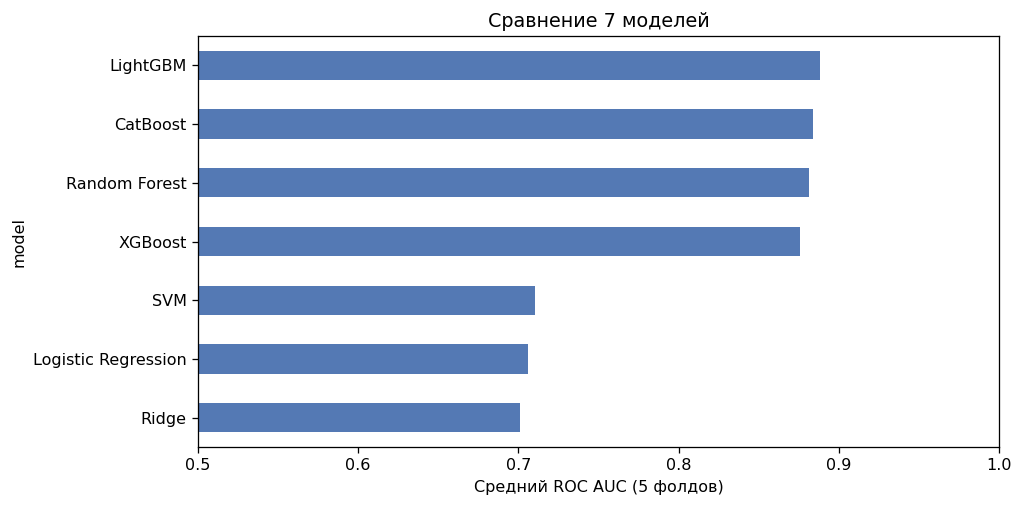

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
base_report.sort_values("mean")["mean"].plot.barh(ax=ax, color="#5479B4")
ax.set(xlabel="Средний ROC AUC (5 фолдов)", title="Сравнение 7 моделей")
ax.set_xlim(0.5, 1.0)
plt.tight_layout()
plt.show()

## 5. Отбор признаков и эксперимент с разнообразием

Мы проверяли сокращение числа признаков, но сильное сокращение до топ-20 ухудшало качество в исходных экспериментах. Поэтому финально **оставляем все 849 таксонов**. Дополнительно честно проверяем только одну маленькую группу — **четыре признака разнообразия**, не удаляя исходные признаки. Базовый CatBoost и версия с diversity обучаются на **тех же фолдах**.

В итоговых моделях нет supervised feature selection; **не используем корреляции со всем `label` для выбора признаков до CV**.

In [10]:
feature_rows = []
for fold, (tr_idx, va_idx) in enumerate(SPLITS, start=1):
    for name, data in [("Исходные", X_base), ("+ 4 diversity", X_div)]:
        prob = predict_prob("CatBoost", data.iloc[tr_idx], y.iloc[tr_idx], data.iloc[va_idx])
        feature_rows.append({"fold": fold, "feature_set": name,
                             "roc_auc": roc_auc_score(y.iloc[va_idx], prob)})
feature_cv = pd.DataFrame(feature_rows)
feature_table = feature_cv.pivot(index="fold", columns="feature_set", values="roc_auc")
display(feature_table.round(4))
print("Средние ROC AUC:")
print(feature_table.mean().round(4))
print("Разница (+diversity – исходные):",
      round((feature_table["+ 4 diversity"] - feature_table["Исходные"]).mean(), 4))

feature_set,+ 4 diversity,Исходные
fold,,
1,0.9042,0.8937
2,0.8717,0.8630
3,0.9100,0.9199
4,0.8821,0.8792
5,0.8618,0.8618


Средние ROC AUC:
feature_set
+ 4 diversity    0.8859
Исходные         0.8835
dtype: float64
Разница (+diversity – исходные): 0.0024


## 6. Два финальных кандидата на одинаковых фолдах

Сравниваем **регуляризованный Random Forest** и **простой ансамбль CatBoost + LightGBM + Random Forest** (без дополнительной метамодели). В обоих вариантах **857 признаков**, включая четыре diversity. Ансамбль усредняет вероятности с **заранее зафиксированными весами** `0.40 / 0.35 / 0.25` — это не результат настройки по leaderboard.

Важно: в ансамбле Random Forest — базовая версия (300 деревьев), а **отдельный RF — другая, более регуляризованная модель** (1200 деревьев). Это разные модели, обе документированы ниже.

In [11]:
ENSEMBLE_WEIGHTS = {"CatBoost": 0.40, "LightGBM": 0.35, "Random Forest": 0.25}

def predict_ensemble(X_tr, y_tr, X_va):
    preds = {name: predict_prob(name, X_tr, y_tr, X_va)
             for name in ENSEMBLE_WEIGHTS}
    return sum(ENSEMBLE_WEIGHTS[name] * preds[name]
               for name in ENSEMBLE_WEIGHTS)

candidate_rows = []
oof_candidates = {"Random Forest (рег.)": np.zeros(len(train)),
                  "Ensemble": np.zeros(len(train))}
for fold, (tr_idx, va_idx) in enumerate(SPLITS, start=1):
    tr_x, va_x = X_div.iloc[tr_idx], X_div.iloc[va_idx]
    tr_y, va_y = y.iloc[tr_idx], y.iloc[va_idx]
    proba_map = {
        "Random Forest (рег.)": predict_prob("Random Forest (рег.)", tr_x, tr_y, va_x),
        "Ensemble": predict_ensemble(tr_x, tr_y, va_x)
    }
    for name, p in proba_map.items():
        oof_candidates[name][va_idx] = p
        candidate_rows.append({"model": name, "fold": fold,
                               "roc_auc": roc_auc_score(va_y, p)})
    print(f"Завершён фолд {fold}/5: два финальных кандидата")

candidate_cv = pd.DataFrame(candidate_rows)
final_cv = (candidate_cv.groupby("model")["roc_auc"]
            .agg(["mean", "std"]).sort_values("mean", ascending=False))
final_cv["oof_auc"] = {name:roc_auc_score(y, p)
                       for name,p in oof_candidates.items()}
display(final_cv.round(4))
print("Важно: сравнение получено на одних и тех же фолдах.")

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Завершён фолд 1/5: два финальных кандидата


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Завершён фолд 2/5: два финальных кандидата


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Завершён фолд 3/5: два финальных кандидата


... (2 outputs left out)

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Завершён фолд 5/5: два финальных кандидата


,mean,std,oof_auc
model,,,
Ensemble,0.8912,0.0260,0.8938
Random Forest (рег.),0.8857,0.0251,0.8806


Важно: сравнение получено на одних и тех же фолдах.


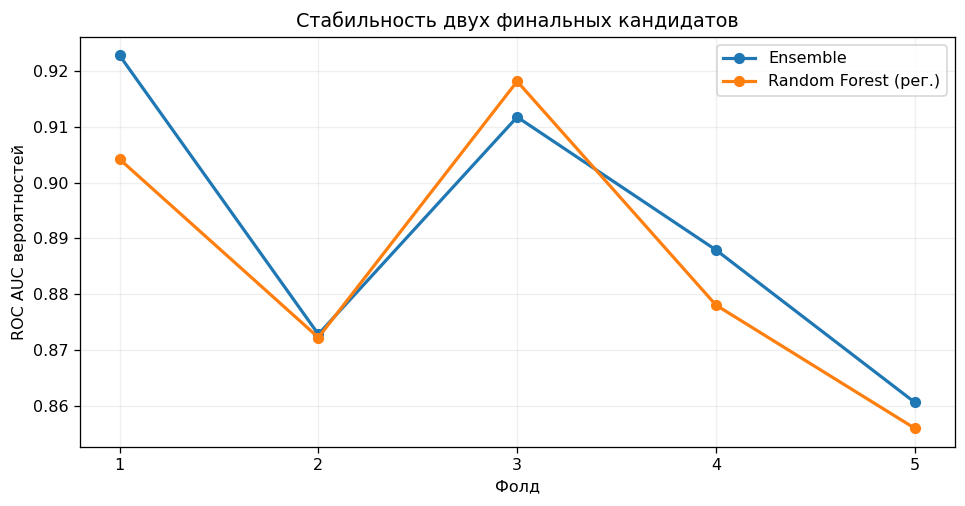

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for name, table in candidate_cv.groupby("model"):
    ax.plot(table["fold"], table["roc_auc"], marker="o", lw=2, label=name)
ax.set(xlabel="Фолд", ylabel="ROC AUC вероятностей",
       title="Стабильность двух финальных кандидатов")
ax.set_xticks(range(1, 6))
ax.grid(alpha=.2)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Стресс-тест: перенос между странами

**Leave-One-Country-Out**: обучаем модель без одной страны и проверяем на полностью исключённой когорте. Это проверяет чувствительность к возможным межстрановым различиям и обычно строже, чем обычная CV. Страна не передаётся моделям как признак.

In [13]:
logo = LeaveOneGroupOut()
loco_rows = []
for tr_idx, va_idx in logo.split(X_div, y, groups=train["cohort"]):
    country = train["cohort"].iloc[va_idx].iloc[0]
    tr_x, va_x = X_div.iloc[tr_idx], X_div.iloc[va_idx]
    tr_y, va_y = y.iloc[tr_idx], y.iloc[va_idx]
    p_rf = predict_prob("Random Forest (рег.)", tr_x, tr_y, va_x)
    p_ens = predict_ensemble(tr_x, tr_y, va_x)
    loco_rows.extend([
        {"country":country, "model":"Random Forest (рег.)", "roc_auc":roc_auc_score(va_y,p_rf)},
        {"country":country, "model":"Ensemble", "roc_auc":roc_auc_score(va_y,p_ens)}
    ])
loco = pd.DataFrame(loco_rows)
loco_pivot = loco.pivot(index="country", columns="model", values="roc_auc")
display(loco_pivot.round(4))
print("Средний LOCO ROC AUC по странам:")
print(loco_pivot.mean().round(4))

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


model,Ensemble,Random Forest (рег.)
country,,
AUS,0.8394,0.8246
CHI,0.8881,0.9108
FRA,0.8567,0.8171
GER,0.8060,0.8282
USA,0.7247,0.7680


Средний LOCO ROC AUC по странам:
model
Ensemble                0.8230
Random Forest (рег.)    0.8297
dtype: float64


## 8. Интерпретация, ограничения и решение

**Интерпретация:** на всём размеченном train обучаем CatBoost только для анализа важностей, затем сопоставляем его top-15 с корреляциями Спирмена. Это **не отбор признаков для CV**, а объяснение модели после экспериментов. Важность CatBoost не задаёт направление эффекта, а Spearman не доказывает причинность.

**Ограничения:** 415 образцов при 849 таксонах; много нулей; различия когорт; возможный спад качества на новых странах; подбор и исследование большого числа гипотез на знакомых фолдах может завышать оценку. Public leaderboard не используем для выбора параметров или весов.

**Финальная стратегия:** по умолчанию выбираем ансамбль, поскольку он использует разные семейства деревьев. Но ниже есть **один переключатель** `FINAL_MODEL`, который позволяет воспроизводимо получить один из двух кандидатов. **Не переключаем его по public LB**.

,CatBoost importance,Spearman
Parvimonas micra [ref_mOTU_v2_1145],12.2847,0.4531
age,4.9550,0.1987
Gemella morbillorum [ref_mOTU_v2_4513],3.8179,0.3945
unknown Peptostreptococcaceae [meta_mOTU_v2_7331],2.5063,-0.1975
unknown Clostridiales [meta_mOTU_v2_6105],2.4889,0.3150
library_size,1.8909,0.1102
unknown Dialister [meta_mOTU_v2_5867],1.7123,0.4097
unknown Clostridiales [meta_mOTU_v2_6602],1.5244,-0.2402
Ruminococcus torques [ref_mOTU_v2_1376],1.5141,0.2686
unknown Porphyromonas [meta_mOTU_v2_7656],1.4767,0.3130


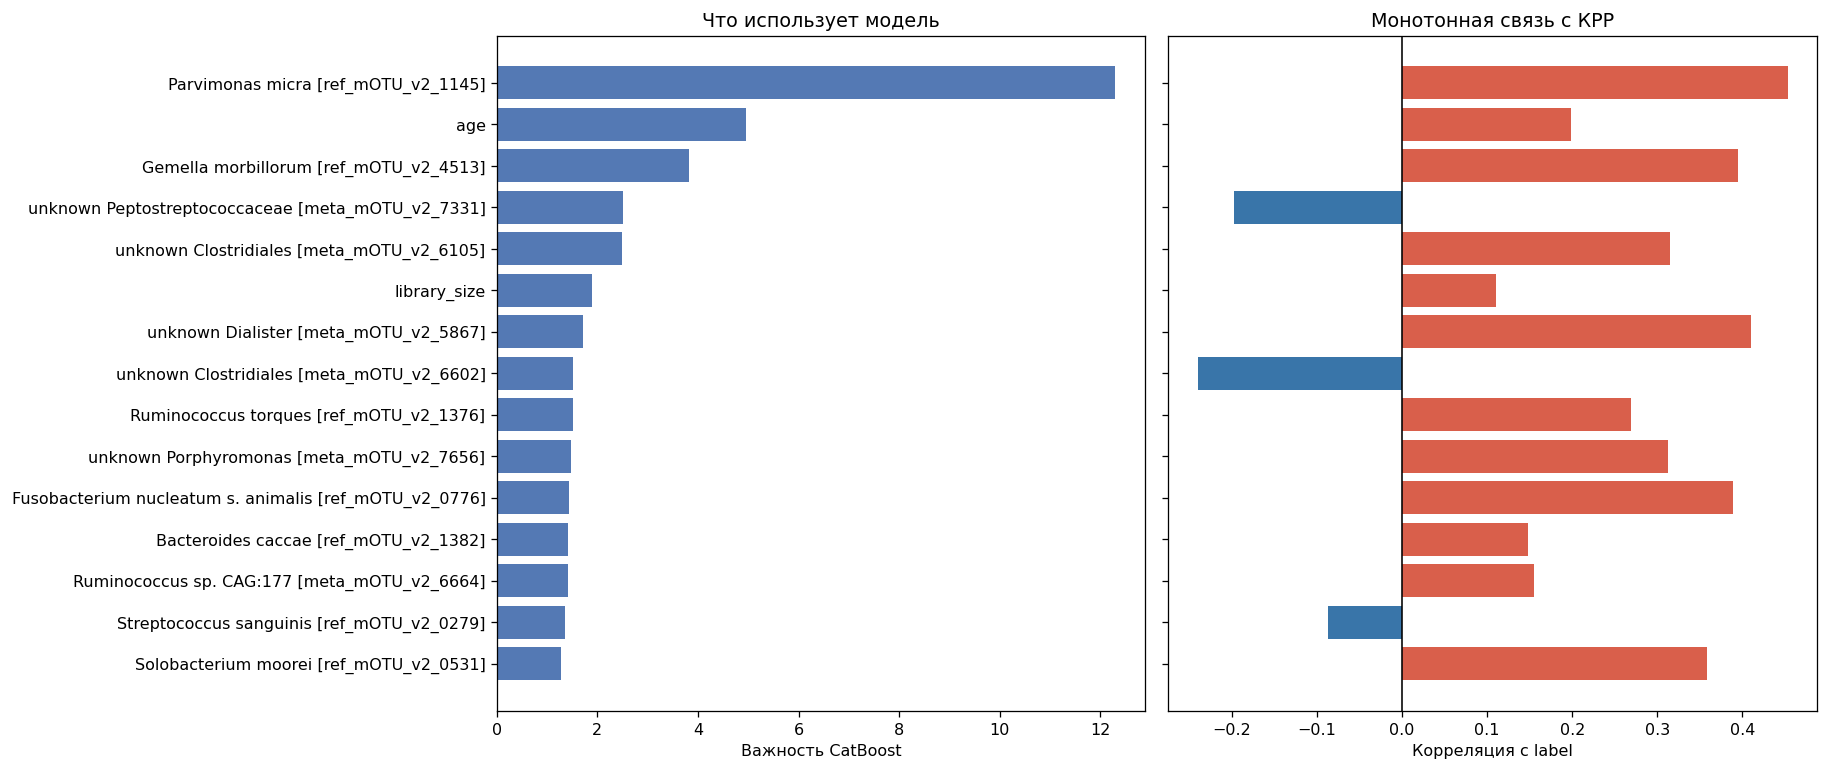

In [14]:
# Только интерпретация, не подбор признаков
imp_all = SimpleImputer(strategy="median", keep_empty_features=True)
X_imp = imp_all.fit_transform(X_div)
cb_interpret = make_model("CatBoost")
cb_interpret.fit(X_imp, y)
importance = pd.Series(cb_interpret.get_feature_importance(), index=X_div.columns)
rho_full = X_div.corrwith(y, method="spearman")
top_features = importance.nlargest(15).index
report_imp = pd.DataFrame({"CatBoost importance":importance.loc[top_features],
                           "Spearman":rho_full.reindex(top_features)})
display(report_imp.round(4))
fig, axes = plt.subplots(1, 2, figsize=(16, 6.8), sharey=True)
ordered = report_imp.sort_values("CatBoost importance")
axes[0].barh(ordered.index, ordered["CatBoost importance"], color="#5479B4")
axes[0].set(xlabel="Важность CatBoost", title="Что использует модель")
axes[1].barh(ordered.index, ordered["Spearman"],
             color=["#D95F4B" if v > 0 else "#3975A9" for v in ordered["Spearman"]])
axes[1].axvline(0, color="black", lw=1)
axes[1].set(xlabel="Корреляция с label", title="Монотонная связь с КРР")
plt.tight_layout()
plt.show()

## 9. Финальное обучение на всех 415 образцах и сохранение сабмита

**В этом разделе впервые читаем `test.csv`.** Он не использовался при CV, EDA и выборе признаков. На всех 415 размеченных образцах обучаем две зафиксированные стратегии и сохраняем **оба** файла. Однако в **последней ячейке** выводится одна таблица, выбранная переключателем — это тот файл, который следует сдавать вместе с **этой версией** ноутбука. Для воспроизводимости не меняйте параметры/seed после сдачи.

Вероятность `label` — непрерывное значение из `[0, 1]`; ROC AUC не требует перевода её в 0/1. В финальных файлах нет других колонок, все `sample_id` уникальны и идут в исходном порядке.

In [15]:
# Укажите один вариант для финальной таблицы: "Ensemble" или "Random Forest (рег.)"
FINAL_MODEL = "Ensemble"
assert FINAL_MODEL in {"Ensemble", "Random Forest (рег.)"}

test = pd.read_csv(DATA_DIR / "test.csv")
assert test["sample_id"].is_unique
assert "label" not in test.columns
assert set(NUM_COLS + ["gender"]).issubset(test.columns)

X_test_div = make_features(test, add_diversity=True)[X_div.columns]

# Две финальные стратегии обучаются только на полном train.
proba_ensemble = predict_ensemble(X_div, y, X_test_div)
proba_rf = predict_prob("Random Forest (рег.)", X_div, y, X_test_div)

submissions = {
    "Ensemble": pd.DataFrame({"sample_id":test["sample_id"], "label":proba_ensemble}),
    "Random Forest (рег.)": pd.DataFrame({"sample_id":test["sample_id"], "label":proba_rf})
}

for name, frame in submissions.items():
    assert frame.columns.tolist() == ["sample_id", "label"]
    assert len(frame) == len(test)
    assert frame["sample_id"].equals(test["sample_id"])
    assert frame["label"].notna().all()
    assert frame["label"].between(0, 1).all()
    path = "submission_ensemble.csv" if name == "Ensemble" else "submission_random_forest.csv"
    frame.to_csv(path, index=False)
    print(name, "сохранён:", path)

submission = submissions[FINAL_MODEL].copy()
submission.to_csv("submission.csv", index=False)
print("Итоговый вариант:", FINAL_MODEL)

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Ensemble сохранён: submission_ensemble.csv
Random Forest (рег.) сохранён: submission_random_forest.csv
Итоговый вариант: Ensemble


### Итоговая таблица для отправки

Последняя ячейка выводит **только** `sample_id` и `label`. Именно `submission.csv` загружается организаторам при выбранном `FINAL_MODEL`.

In [16]:
display(submission[["sample_id", "label"]])

,sample_id,label
0,S0125,0.580823
1,S0242,0.252704
2,S0053,0.140250
3,S0173,0.116470
4,S0453,0.614072
...,...,...
155,S0491,0.829431
156,S0360,0.763134
157,S0192,0.759653
158,S0005,0.855956


## 10. Финальное решение и F1-порог

Финальная модель усредняет две независимые вероятности:

1. Cohort-aware CLR-логистическая регрессия: общая модель обучается на всех пациентах, а для представленных стран усредняется с локальной моделью соответствующей когорты.
2. ExtraTrees: логарифмированные относительные численности, признаки разнообразия и метаданные; 300 признаков отбираются только внутри обучающей части.

Для презентации ниже используется одно фиксированное разбиение 80/20, стратифицированное по `cohort × label`. Порог классификации подбирается по F1 через 5-fold OOF-предсказания **только на 80% train-части**, затем фиксированный порог применяется к отложенным 20%. Поэтому confusion matrix не использовалась для выбора порога.

ROC AUC оценивает ранжирование вероятностей; F1 и confusion matrix зависят от выбранного порога. В итоговом CSV сохраняются именно вероятности, а не бинарные классы.

In [1]:
# ===== Финальное решение: cohort-aware CLR + ExtraTrees =====
# Эта секция самодостаточна: она не зависит от предыдущих экспериментов ноутбука.
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, classification_report, confusion_matrix,
    f1_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from IPython.display import display

FINAL_SEED = 2026
FINAL_N_JOBS = 4
FINAL_DATA_DIR = Path("/content") if Path("/content/train.csv").exists() else Path(".")
if not (FINAL_DATA_DIR / "train.csv").exists():
    raise FileNotFoundError("Положите train.csv и test.csv рядом с ноутбуком или в /content.")
final_train = pd.read_csv(FINAL_DATA_DIR / "train.csv")
final_test = pd.read_csv(FINAL_DATA_DIR / "test.csv")
FINAL_META = ["cohort", "age", "gender", "bmi", "library_size"]
FINAL_TAXA = [c for c in final_train.columns if c not in ["sample_id", "label", *FINAL_META]]
assert set(final_train.columns) - {"label"} == set(final_test.columns)
assert final_train.sample_id.is_unique and final_test.sample_id.is_unique
assert final_train[FINAL_TAXA].min().min() >= 0
print(f"train: {final_train.shape}; test: {final_test.shape}; taxa: {len(FINAL_TAXA)}")


class FinalMicrobiomeFeatures(BaseEstimator):
    """Train-fitted prevalence filter, compositional transform and metadata features."""
    def __init__(self, mode="clr", engineered=False, metadata=True, min_prevalence=0.02):
        self.mode = mode
        self.engineered = engineered
        self.metadata = metadata
        self.min_prevalence = min_prevalence

    def fit(self, X, y=None):
        self.taxa_ = [c for c in FINAL_TAXA if (X[c].fillna(0) > 0).mean() >= self.min_prevalence]
        return self

    def transform(self, X):
        abundance = X[self.taxa_].fillna(0).to_numpy(dtype=float).clip(0)
        proportions = abundance / np.maximum(abundance.sum(axis=1, keepdims=True), 1e-12)
        if self.mode == "clr":
            values = np.log(proportions + 1e-6)
            values -= values.mean(axis=1, keepdims=True)
        elif self.mode == "log":
            values = np.log1p(10000 * proportions)
        else:
            values = abundance
        result = pd.DataFrame(values, index=X.index, columns=self.taxa_)
        if self.engineered:
            h = -(proportions * np.log(np.maximum(proportions, 1e-12))).sum(axis=1)
            richness = (abundance > 0).sum(axis=1)
            concentration = (proportions ** 2).sum(axis=1)
            ordered = np.sort(proportions, axis=1)
            extra = pd.DataFrame({
                "bio_richness": richness,
                "bio_shannon": h,
                "bio_simpson": 1 - concentration,
                "bio_effective_taxa": np.exp(h),
                "bio_evenness": h / np.log(np.maximum(richness, 2)),
                "bio_dominance": proportions.max(axis=1),
                "bio_top5": ordered[:, -5:].sum(axis=1),
                "bio_top10": ordered[:, -10:].sum(axis=1),
            }, index=X.index)
            result = pd.concat([result, extra], axis=1)
        if self.metadata:
            meta = X[FINAL_META].copy()
            meta["library_size"] = np.log1p(meta["library_size"])
            meta["bmi_missing"] = meta["bmi"].isna().astype(int)
            result = pd.concat([result, meta], axis=1)
        return result


class FinalPrevalenceFilter(BaseEstimator):
    def fit(self, X, y=None):
        self.columns_ = [c for c in X.columns if X[c].nunique(dropna=False) > 1]
        return self

    def transform(self, X):
        return X[self.columns_]


def make_prepare(scale):
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler() if scale else "passthrough"),
    ])
    return ColumnTransformer([
        ("num", numeric, lambda frame: frame.select_dtypes(include=np.number).columns),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         lambda frame: frame.select_dtypes(exclude=np.number).columns),
    ], sparse_threshold=0)


def make_clr_logistic(C, with_metadata):
    return Pipeline([
        ("features", FinalMicrobiomeFeatures(mode="clr", metadata=with_metadata)),
        ("clean", FinalPrevalenceFilter()),
        ("prepare", make_prepare(scale=True)),
        ("model", LogisticRegression(C=C, solver="liblinear", max_iter=3000, random_state=FINAL_SEED)),
    ])


def make_extra_trees():
    return Pipeline([
        ("features", FinalMicrobiomeFeatures(mode="log", engineered=True, metadata=True)),
        ("clean", FinalPrevalenceFilter()),
        ("prepare", make_prepare(scale=False)),
        ("select", SelectKBest(f_classif, k=300)),
        ("model", ExtraTreesClassifier(
            n_estimators=700, min_samples_leaf=1, max_features=0.4,
            n_jobs=FINAL_N_JOBS, random_state=FINAL_SEED,
        )),
    ])


class CohortAwareCLR(ClassifierMixin, BaseEstimator):
    """Среднее общей CLR-модели и модели соответствующей когорты.

    Для невидимой когорты используется только общая модель.
    """
    def __init__(self, C=0.03, local_weight=0.5, min_local_samples=25):
        self.C = C
        self.local_weight = local_weight
        self.min_local_samples = min_local_samples

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.array([0, 1])
        self.global_model_ = make_clr_logistic(self.C, with_metadata=True).fit(X, y)
        self.local_models_ = {}
        for cohort in X["cohort"].dropna().unique():
            positions = np.flatnonzero((X["cohort"] == cohort).to_numpy())
            if len(positions) >= self.min_local_samples and len(np.unique(y[positions])) == 2:
                self.local_models_[cohort] = make_clr_logistic(self.C, with_metadata=False).fit(X.iloc[positions], y[positions])
        return self

    def predict_proba(self, X):
        probability = self.global_model_.predict_proba(X)[:, 1]
        for cohort, model in self.local_models_.items():
            positions = np.flatnonzero((X["cohort"] == cohort).to_numpy())
            if len(positions):
                local_probability = model.predict_proba(X.iloc[positions])[:, 1]
                probability[positions] = ((1 - self.local_weight) * probability[positions]
                                          + self.local_weight * local_probability)
        return np.column_stack([1 - probability, probability])


def make_final_ensemble():
    return {
        "cohort_clr": CohortAwareCLR(C=0.03, local_weight=0.5),
        "extra_trees": make_extra_trees(),
    }


def fit_ensemble_predict(components, X_fit, y_fit, X_predict):
    fitted = {name: model.fit(X_fit, y_fit) for name, model in components.items()}
    probabilities = [model.predict_proba(X_predict)[:, 1] for model in fitted.values()]
    return np.mean(probabilities, axis=0), fitted


train: (415, 856); test: (160, 855); taxa: 849


In [2]:
# ===== Одно train/validation-разбиение =====
# Это единственный внешний validation split. Стратификация сохраняет cohort × label.
final_X = final_train.drop(columns=["label", "sample_id"])
final_y = final_train["label"].astype(int).to_numpy()
final_X_test = final_test[final_X.columns].copy()
final_strata = final_X["cohort"].astype(str) + "_" + pd.Series(final_y, index=final_X.index).astype(str)
splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=FINAL_SEED)
final_train_idx, final_val_idx = next(splitter.split(final_X, final_strata))
X_train_split, X_val_split = final_X.iloc[final_train_idx], final_X.iloc[final_val_idx]
y_train_split, y_val_split = final_y[final_train_idx], final_y[final_val_idx]
print(f"train split: {len(X_train_split)}; validation split: {len(X_val_split)}")
display(pd.crosstab(final_X.iloc[final_val_idx]["cohort"], y_val_split, margins=True))

# Модель видит validation только в predict_proba ниже.
validation_probability, validation_fitted_models = fit_ensemble_predict(
    make_final_ensemble(), X_train_split, y_train_split, X_val_split
)
print(f"Validation ROC AUC: {roc_auc_score(y_val_split, validation_probability):.4f}")


train split: 332; validation split: 83
col_0    0   1  All
cohort             
AUS     10   6   16
CHI      8  11   19
FRA      9   7   16
GER      9   9   18
USA      7   7   14
All     43  40   83
Validation ROC AUC: 0.9413


inner fold 1/5 complete
inner fold 2/5 complete
inner fold 3/5 complete
inner fold 4/5 complete
inner fold 5/5 complete
OOF F1-optimal threshold: 0.449; OOF F1: 0.8260


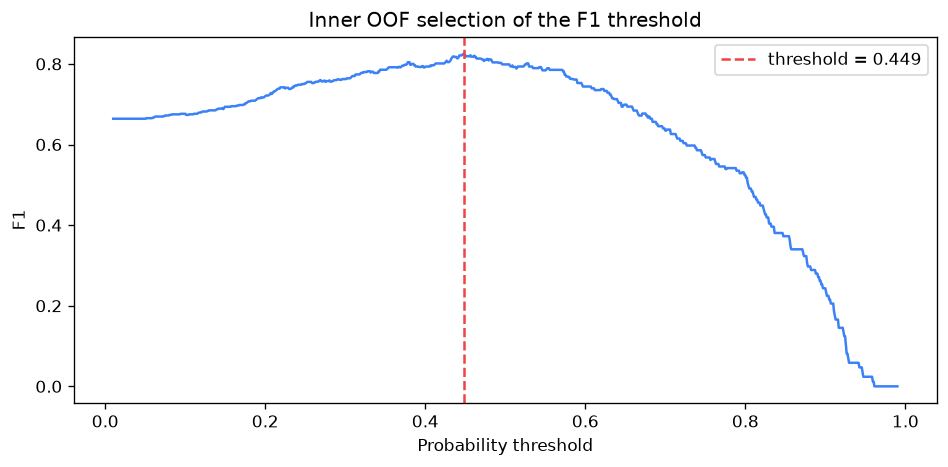

In [3]:
# ===== Подбор F1-порога на train через внутренние OOF-предсказания =====
# Порог не подбирается по validation. Для каждого из 5 внутренних фолдов модель
# обучается только на оставшихся строках внешнего train split.
inner_strata = X_train_split["cohort"].astype(str) + "_" + pd.Series(y_train_split, index=X_train_split.index).astype(str)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=FINAL_SEED)
train_oof_probability = np.full(len(X_train_split), np.nan)
for fold, (inner_fit, inner_holdout) in enumerate(inner_cv.split(X_train_split, inner_strata), start=1):
    fold_probability, _ = fit_ensemble_predict(
        make_final_ensemble(),
        X_train_split.iloc[inner_fit], y_train_split[inner_fit], X_train_split.iloc[inner_holdout]
    )
    train_oof_probability[inner_holdout] = fold_probability
    print(f"inner fold {fold}/5 complete")
assert np.isfinite(train_oof_probability).all()

threshold_grid = np.linspace(0.01, 0.99, 991)
f1_values = np.array([f1_score(y_train_split, train_oof_probability >= threshold) for threshold in threshold_grid])
best_position = int(np.argmax(f1_values))
F1_THRESHOLD = float(threshold_grid[best_position])
print(f"OOF F1-optimal threshold: {F1_THRESHOLD:.3f}; OOF F1: {f1_values[best_position]:.4f}")

fig, axis = plt.subplots(figsize=(8, 4))
axis.plot(threshold_grid, f1_values, color="#3B82F6")
axis.axvline(F1_THRESHOLD, color="#EF4444", ls="--", label=f"threshold = {F1_THRESHOLD:.3f}")
axis.set(xlabel="Probability threshold", ylabel="F1", title="Inner OOF selection of the F1 threshold")
axis.legend()
plt.tight_layout()
plt.show()


Validation F1 at threshold 0.449: 0.8861
              precision    recall  f1-score   support

           0      0.886     0.907     0.897        43
           1      0.897     0.875     0.886        40

    accuracy                          0.892        83
   macro avg      0.892     0.891     0.891        83
weighted avg      0.892     0.892     0.892        83

          Predicted 0  Predicted 1
Actual 0           39            4
Actual 1            5           35


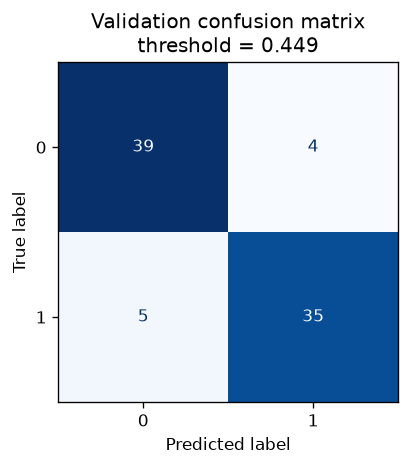

In [4]:
# ===== Итог на отложенной validation =====
validation_prediction = (validation_probability >= F1_THRESHOLD).astype(int)
validation_f1 = f1_score(y_val_split, validation_prediction)
validation_matrix = confusion_matrix(y_val_split, validation_prediction, labels=[0, 1])
print(f"Validation F1 at threshold {F1_THRESHOLD:.3f}: {validation_f1:.4f}")
print(classification_report(y_val_split, validation_prediction, digits=3, zero_division=0))

display(pd.DataFrame(
    validation_matrix,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"],
))
figure, axis = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(validation_matrix, display_labels=["0", "1"]).plot(ax=axis, cmap="Blues", colorbar=False)
axis.set_title(f"Validation confusion matrix\nthreshold = {F1_THRESHOLD:.3f}")
plt.tight_layout()
plt.show()


In [5]:
# ===== Обучение на всех train-строках и финальный submission =====
# Здесь F1-порог не применяется: конкурсный CSV требует непрерывные вероятности.
final_test_probability, final_fitted_models = fit_ensemble_predict(
    make_final_ensemble(), final_X, final_y, final_X_test
)
final_submission = pd.DataFrame({"sample_id": final_test["sample_id"], "label": final_test_probability})
assert len(final_submission) == len(final_test)
assert final_submission["sample_id"].tolist() == final_test["sample_id"].tolist()
assert final_submission["label"].between(0, 1).all()
FINAL_OUTPUT = FINAL_DATA_DIR / "submission_final_cohort_et.csv"
final_submission.to_csv(FINAL_OUTPUT, index=False)
display(final_submission.head())
print(f"Saved {len(final_submission)} probability predictions to: {FINAL_OUTPUT.resolve()}")


  sample_id     label
0     S0125  0.396793
1     S0242  0.284042
2     S0053  0.316507
3     S0173  0.209528
4     S0453  0.639920
Saved 160 probability predictions to: C:\Users\u0910\Documents\Codex\2026-11-22\files-mentioned-by-the-user-test\work\data\submission_final_cohort_et.csv


### ROC-кривая финальной модели

Кривая строится по вероятностям финального ансамбля на отложенной validation-части. AUC не зависит от F1-порога; выбранный выше порог используется только для классификации и confusion matrix.

Validation ROC AUC: 0.9413


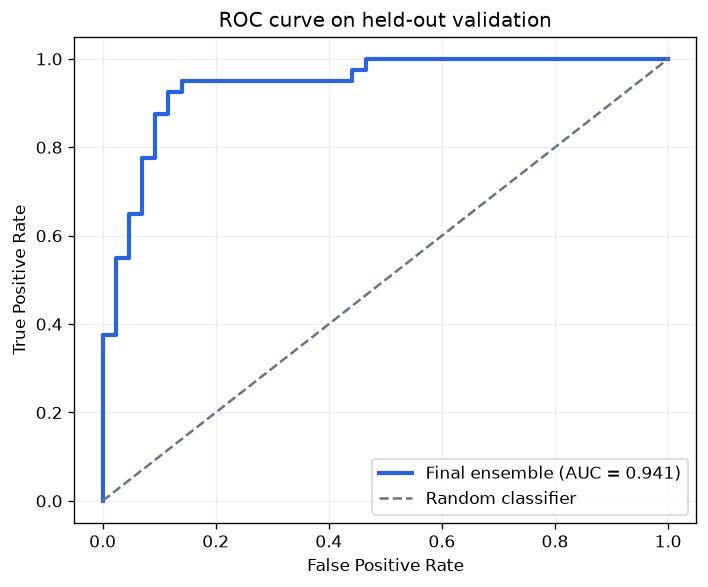

In [6]:
# ===== ROC-кривая финальной модели на отложенной validation =====
from sklearn.metrics import roc_auc_score, roc_curve

roc_fpr, roc_tpr, _ = roc_curve(y_val_split, validation_probability)
roc_auc_value = roc_auc_score(y_val_split, validation_probability)
figure, axis = plt.subplots(figsize=(6, 5))
axis.plot(roc_fpr, roc_tpr, color="#2563EB", lw=2.5, label=f"Final ensemble (AUC = {roc_auc_value:.3f})")
axis.plot([0, 1], [0, 1], color="#6B7280", lw=1.5, ls="--", label="Random classifier")
axis.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC curve on held-out validation")
axis.legend(loc="lower right")
axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print(f"Validation ROC AUC: {roc_auc_value:.4f}")
